# BSISO_daily_ERE_Prediction

**Forecasting the daily chance of a large extreme-rain event (ERE) over central India, 1-14 days ahead, from the
BSISO alone.** This is the final, cleaned-up version of *one* approach we tried in Part 2 of the project
("Arm A": BSISO history only, no weather maps, no rain inputs). It retrains the best model found in seven test
rounds (R1, R1b, R2-R6, Nov 2026), reproduces all its scores and statistical comparisons, adds the weekly view,
and re-scores every change we tested.

## The pipeline in two steps
1. **Forecast the BSISO.** A small transformer reads the last 60 days of BSISO1 (PC1, PC2), BSISO2 (PC3, PC4) and
   the time of year, and forecasts BSISO1 for each of the next 10 days.
2. **BSISO -> rain chances.** For target day T, the BSISO forecast for T-5 (the BSISO leads ERE days by ~5 days)
   goes into a cumulative logistic regression with the normal seasonal chance of the date. Output: daily
   P(no ERE), P(16-39 cells), P(40-90 cells), P(91+ cells). Weekly: P(0, 1, 2+ ERE days in the week).

## Data (Kaggle datasets)
- `BSISO.INDEX.NORM.LY.data` - daily BSISO1/BSISO2 PCs, 1981-2026 (Lee et al. 2013 index, APCC)
- `imerg_india_025_jjas_2000_2024.nc` - IMERG daily rain, 0.25 deg, June-September 2000-2024
- `india_mask_025.npy` - India land mask
- `lasso_bsiso_forecasts.parquet` - the old lasso BSISO forecasts (baseline)
- outputs of the test-round notebooks `bsiso-forecast-tests-r1 ... r6, r1b` (only for the "what mattered" section)

**ERE day** = at least one 8-connected cluster of >= 16 IMERG cells, each above its own wet-day 99th percentile
(50 mm floor), centred in central India (17-26.5N, 74-88.5E). Happens on 15.3% of JJAS days.
Size classes by the largest cluster: no ERE / 16-39 / 40-90 / 91+ cells.

## The model ("T best")
Patch transformer (after PatchTST, Nie et al. 2023): 60 days cut into twelve 5-day tokens, width 64, 4 heads,
3 pre-norm layers, about 121k parameters, plus a linear shortcut from the PC1/PC2 history (after DLinear).
Loss = 0.5 x MSE + 0.5 x error in amplitude (after Anirudh et al. 2025). AdamW, early stopping, 20 seeds averaged.

## How it is tested (no peeking)
- BSISO step: years split into 5 blocks (1981-90, 91-99, 2000-08, 09-17, 18-26); each block is forecast by
  models trained on the other four. Scored on JJAS 2000-2024 target days.
- Rain step: each summer is predicted by a regression fitted on the other 24 summers.
- Scores: RPSS (0 = normal chance), correlation and AUC of P(large ERE), hit rates, reliability, Brier skill.
- Error bars: 90% ranges from resampling years 2,000 times. Fair baseline = ridge regression on the same inputs.

## Results (from the test rounds; this notebook reproduces them)
| rain lead (days) | 1-5 (true BSISO) | 8 | 10 | 12 | 14 |
|---|---|---|---|---|---|
| RPSS, transformer | 0.035 | 0.044 | 0.037 | 0.028 | 0.023 |
| RPSS, ridge (same inputs) | 0.035 | 0.036 | 0.029 | 0.020 | 0.017 |
| RPSS, lasso (old model) | 0.035 | 0.032 | 0.025 | 0.013 | 0.009 |
| corr of P(large ERE) with ERE days | 0.245 | 0.268 | 0.251 | 0.229 | 0.215 |
| AUC | 0.699 | 0.710 | 0.692 | 0.676 | 0.664 |
| ERE rate on the 10% of days rated most likely (normal 15%) | 29% | 34% | 35% | 35% | 34% |

Normal chance alone: corr 0.140, AUC 0.610. Transformer minus ridge (RPSS): +0.008 [+0.003, +0.013] at 8 d,
+0.007 [-0.000, +0.014] at 10 d, +0.008 [+0.001, +0.015] at 12 d, +0.006 [-0.001, +0.014] at 14 d.

**Weekly view (same forecasts summed over a week; section 8):**

| window | RPSS (0/1/2+ ERE days) | corr, expected vs observed count | AUC any ERE day | AUC 2+ days |
|---|---|---|---|---|
| week 1 (days 1-7), transformer | 0.133 | 0.44 | 0.76 | 0.75 |
| week 2 (days 8-14), transformer | 0.081 | 0.42 | 0.72 | 0.72 |
| week 2, ridge (same inputs) | 0.058 | 0.38 | 0.71 | 0.69 |
| week 2, true BSISO 5 days before (perfect) | 0.129 | 0.44 | 0.76 | 0.75 |

Normal chance alone: corr 0.23. Week 2, transformer minus ridge: +0.022 [+0.008, +0.036] RPSS - the transformer's
edge is clearer weekly than daily.

**BSISO forecast itself:** the transformer is *not* a better BSISO forecaster than ridge (correlation 0.62 vs 0.63
at 5 d, 0.46 vs 0.46 at 9 d; both reach the 0.5 "useful" level at about 7.5 days). Its advantage is that it keeps
the oscillation's strength (74% vs 38% at 9 d), and that is what helps the rain step.

**What mattered** (section 9): BSISO2 input (-0.008 RPSS without it), season input (-0.004), amplitude weight
0.5 (+0.002 over 0.2), 60-day window (90 d: -0.005). Larger models, encoder-decoder, GRU, uncertainty outputs,
summer/lead weighting, dropout, token length, helper tasks: no gain or worse.

## Honest limits
- A daily correlation near 0.25 is close to the maximum for this event: BSISO moves the daily ERE chance between
  ~4% and ~28%, and correct probabilities that never go higher cannot correlate much above ~0.3 with yes/no days.
- The largest class (91+ cells) loses its signal fastest (AUC 0.73 with the true BSISO, 0.53 at 14 d).
- The transformer beats "true BSISO 5 days before" at 6-8 d (+0.006 / +0.009 RPSS) but not significantly.

## Outputs (in /kaggle/working)
`daily_ere_class_probabilities.csv`, `weekly_ere_count_probabilities.csv`, `bsiso_forecasts.parquet`,
`bsiso_scores.csv`, `bsiso_comparisons.csv`, `rain_scores.csv`, `rain_comparisons.csv`,
`rain_accuracy_by_lead.csv`, `weekly_scores.csv`, `weekly_comparisons.csv`, `what_mattered.csv`,
`amplitude_weight.csv`, `training_log.csv`, `fig1-fig6 *.png`, `ckpt/` (every trained model's forecasts;
a re-run that finds them skips training).

### Settings

In [1]:
# CELL 1 -- settings
N_SEEDS = 20                                                       # trained copies averaged (10 is already enough)
FINAL = dict(d=64, heads=4, layers=3, ff=128, win=60, patch=5, drop=0.1, amp_w=0.5)
TAG = "FINAL"                                                      # checkpoint name prefix

### Setup, data and the ere days

In [2]:
# CELL 2 -- setup, data and the ERE days
import os, glob, time, math, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.dates
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.linear_model import RidgeCV
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
from IPython.display import display

warnings.filterwarnings("ignore")
ROOTS = [r for r in os.environ.get("BSISO_DATA", "/kaggle/input").split(os.pathsep) if r]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
FAST = os.environ.get("FAST") == "1"                               # quick local check: 1 seed, 2 epochs
if FAST:
    N_SEEDS = 1
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def find(pattern, required=True):
    for r in ROOTS:
        hits = sorted(glob.glob(os.path.join(r, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(f"{pattern} not found in the attached datasets")
    return None


SURF, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29d"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 10.5,
    "axes.titlelocation": "left", "lines.linewidth": 2, "lines.markersize": 5})

b = pd.read_csv(find("BSISO.INDEX.NORM.LY.data"), sep=r"\s+", skiprows=1, header=None,
                names=["year", "doy", "p1", "p2", "q1", "q2", "a1", "a2"]).replace(-999.9, np.nan)
b["date"] = pd.to_datetime(b["year"] * 1000 + b["doy"], format="%Y%j")
b = b.set_index("date").asfreq("D")
b[["p1", "p2", "q1", "q2"]] = b[["p1", "p2", "q1", "q2"]].interpolate(limit=2, limit_area="inside")
DATES = b.index
doy = DATES.dayofyear.values
FEAT = np.column_stack([b[["p1", "p2", "q1", "q2"]].values, np.sin(2 * np.pi * doy / 365.25),
                        np.cos(2 * np.pi * doy / 365.25)]).astype("float32")   # BSISO1, BSISO2, season
PCS = b[["p1", "p2"]].values.astype("float32")

ds = xr.open_dataset(find("imerg_india_025_jjas_2000_2024.nc"))
tp = ds["tp"].values.astype("float32")
lat, lon = ds["lat"].values, ds["lon"].values
times = pd.DatetimeIndex(ds["time"].values).normalize()
ds.close()
mask = np.load(find("india_mask_025.npy"))
years = times.year.values
NYR, ND = len(np.unique(years)), len(set(times.strftime("%m%d")))
kidx = np.tile(np.arange(ND), NYR)
THR = np.maximum(np.nanpercentile(np.where(tp > 1, tp, np.nan), 99, axis=0), 50).astype("float32")
LA2, LO2 = np.meshgrid(lat, lon, indexing="ij")
MXS = np.zeros(len(times))
for t in range(len(times)):
    L, n = ndimage.label(mask & (tp[t] > THR), structure=np.ones((3, 3)))
    if n:
        idx = np.arange(1, n + 1)
        sz = ndimage.sum(np.ones_like(THR), L, idx)
        la, lo = np.array(ndimage.mean(LA2, L, idx)), np.array(ndimage.mean(LO2, L, idx))
        ci = (la >= 17) & (la < 26.5) & (lo >= 74) & (lo <= 88.5) & ~((lo <= 77.5) & (la <= 21))
        if (ci & (sz >= 16)).any():
            MXS[t] = sz[ci & (sz >= 16)].max()
del tp
CLS4 = np.digitize(MXS, [16, 40, 91])                              # 0 none, 1 16-39, 2 40-90, 3 91+ cells
CNAMES = ["no ERE", "16-39 cells", "40-90 cells", "91+ cells"]
OBS1 = (CLS4 > 0).astype(float)
print(f"device {DEV}" + (f" ({torch.cuda.get_device_name(0)})" if DEV.type == "cuda" else "") +
      f" | {len(times):,} JJAS days, ERE on {OBS1.mean():.1%}: " +
      ", ".join(f"{c} {np.mean(CLS4 == i):.1%}" for i, c in enumerate(CNAMES)))

device cpu | 3,050 JJAS days, ERE on 15.3%: no ERE 84.7%, 16-39 cells 8.9%, 40-90 cells 5.0%, 91+ cells 1.4%


### Forecast samples (60 days in, 10 days out) and year blocks

In [3]:
# CELL 3 -- forecast samples (60 days in, 10 days out) and year blocks
WMAX, H = 60, 10
tt = np.arange(WMAX - 1, len(DATES) - H)
tt = tt[np.array([np.isfinite(FEAT[t - WMAX + 1:t + H + 1]).all() for t in tt])]
X = np.stack([FEAT[t - WMAX + 1:t + 1] for t in tt])
Y = np.stack([PCS[t + 1:t + H + 1] for t in tt])
ISSUE = DATES[tt]
uyr = np.unique(ISSUE.year)
BLK = np.array([{y: i * 5 // len(uyr) for i, y in enumerate(uyr)}[y] for y in ISSUE.year])
Xt, Yt = torch.tensor(X).to(DEV), torch.tensor(Y).to(DEV)
print(f"{len(tt):,} samples, blocks: " + ", ".join(f"{ISSUE.year[BLK == k].min()}-{ISSUE.year[BLK == k].max()}"
                                                  for k in range(5)))

16,552 samples, blocks: 1981-1990, 1991-1999, 2000-2008, 2009-2017, 2018-2026


### The model

In [4]:
# CELL 4 -- the model
class PatchModel(nn.Module):
    """Encoder-only patch transformer (after PatchTST, Nie et al. 2023): 5-day tokens of all 6 inputs, direct
    1-10 day head, plus a linear path from the PC1/PC2 history (after DLinear, Zeng et al. 2023)."""
    def __init__(self, win, d, heads, layers, ff, patch=5, drop=0.1, **_):
        super().__init__()
        self.win, self.np_ = win, win // patch
        self.embed = nn.Linear(patch * 6, d)
        self.pos = nn.Parameter(torch.zeros(1, self.np_, d))
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True,
                                                                    norm_first=True), layers)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(self.np_ * d, H * 2)
        self.lin = nn.Linear(win * 2, H * 2)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)   # starts as the linear model

    def forward(self, x):
        x = x[:, -self.win:]
        B = x.shape[0]
        z = self.norm(self.enc(self.embed(x.reshape(B, self.np_, -1)) + self.pos)).reshape(B, -1)
        return (self.head(z) + self.lin(x[:, :, :2].reshape(B, -1))).reshape(B, H, 2)


print(f"transformer: {sum(p.numel() for p in PatchModel(**FINAL).parameters()):,} parameters")

transformer: 121,096 parameters


### Training (5 year blocks x seeds) and the baselines

In [5]:
# CELL 5 -- training (5 year blocks x seeds) and the baselines
MAXEP, PATIENCE, BATCH = (2, 2, 256) if FAST else (200, 15, 256)


def loss_fn(p, y, amp_w):
    """(1 - amp_w) x MSE on (PC1, PC2) + amp_w x MSE on the amplitude."""
    amp = lambda v: torch.sqrt((v ** 2).sum(-1) + 1e-6)
    return (1 - amp_w) * ((p - y) ** 2).mean() + amp_w * ((amp(p) - amp(y)) ** 2).mean()


def train_one(tr, va, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    if FAST:
        tr, va = tr[:3000], va[:800]
    m = PatchModel(**FINAL).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    trt = torch.tensor(tr, device=DEV)
    best, bad, state = np.inf, 0, None
    for ep in range(MAXEP):
        m.train()
        perm = trt[torch.randperm(len(trt), device=DEV)]
        for i in range(0, len(perm), BATCH):
            j = perm[i:i + BATCH]
            opt.zero_grad()
            loss_fn(m(Xt[j]), Yt[j], FINAL["amp_w"]).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
        m.eval()
        with torch.no_grad():
            v = np.mean([loss_fn(m(Xt[va[i:i + 2048]]), Yt[va[i:i + 2048]], FINAL["amp_w"]).item()
                         for i in range(0, len(va), 2048)])
        sched.step(v)
        if v < best - 1e-5:
            best, bad, state = v, 0, {k: w.detach().clone() for k, w in m.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    m.load_state_dict(state)
    m.eval()
    return m, ep + 1


FC = {"persistence": np.repeat(X[:, -1:, :2], H, axis=1)}          # BSISO on the issue day, kept constant
for nm, Xf in (("ridge", X[:, :, :2].reshape(len(X), -1)), ("ridge, all inputs", X.reshape(len(X), -1))):
    P = np.zeros_like(Y)
    for k in range(5):
        te, tr = BLK == k, BLK != k
        P[te] = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(Xf[tr], Y[tr].reshape(tr.sum(), -1)).predict(Xf[te]).reshape(-1, H, 2)
    FC[nm] = P
lz = find("lasso_bsiso_forecasts.parquet", required=False)
if lz:
    LZ = pd.read_parquet(lz).set_index(["lead", "issue"])[["f1", "f2"]]
    P = np.full_like(Y, np.nan)
    for L in range(1, H + 1):
        P[:, L - 1] = LZ.reindex(pd.MultiIndex.from_arrays([np.full(len(ISSUE), L), ISSUE])).values
    FC["lasso"] = P
rng = np.random.default_rng(0)
VA_YEARS = {k: rng.choice(np.unique(ISSUE.year[BLK != k]), max(2, len(np.unique(ISSUE.year[BLK != k])) // 7),
                          replace=False) for k in range(5)}       # ~15% of training years for early stopping
CKPT = os.path.join(OUT, "ckpt")
os.makedirs(CKPT, exist_ok=True)
CK_FOUND = {os.path.basename(f): f for r in ROOTS for f in glob.glob(os.path.join(r, "**", "ckpt", f"{TAG}_*.npz"), recursive=True)}
CK_FOUND.update({os.path.basename(f): f for f in glob.glob(os.path.join(CKPT, f"{TAG}_*.npz"))})
print(f"checkpoints found from earlier runs: {len(CK_FOUND)}")
LOG, P, t0 = [], np.zeros_like(Y), time.time()
for k in range(5):
    te = np.where(BLK == k)[0]
    va = np.where((BLK != k) & np.isin(ISSUE.year, VA_YEARS[k]))[0]
    tr = np.where((BLK != k) & ~np.isin(ISSUE.year, VA_YEARS[k]))[0]
    preds = []
    for s in range(N_SEEDS):
        key = f"{TAG}_b{k}_s{s}{'_fast' if FAST else ''}.npz"
        if key in CK_FOUND:                                        # finished before: reuse
            z = np.load(CK_FOUND[key]); pred, ne = z["pred"], int(z["epochs"])
            if not os.path.exists(os.path.join(CKPT, key)):
                np.savez(os.path.join(CKPT, key), pred=pred, epochs=ne)
        else:
            m, ne = train_one(tr, va, s)
            with torch.no_grad():
                pred = np.concatenate([m(Xt[te[i:i + 2048]]).cpu().numpy() for i in range(0, len(te), 2048)])
            np.savez(os.path.join(CKPT, key), pred=pred, epochs=ne)   # saved at once: nothing lost if cut off
        preds.append(pred)
        LOG.append({"block": k, "seed": s, "epochs": ne})
    P[te] = np.mean(preds, axis=0)
    print(f"block {k + 1}/5 done ({(time.time() - t0) / 60:.1f} min)", flush=True)
FC["transformer"] = P
MODELS = ["transformer", "ridge, all inputs", "ridge", "lasso", "persistence"]
MODELS = [m for m in MODELS if m in FC]
pd.DataFrame(LOG).to_csv(os.path.join(OUT, "training_log.csv"), index=False)
pd.concat([pd.DataFrame({"model": nm, "issue": np.repeat(ISSUE, H), "lead": np.tile(np.arange(1, H + 1), len(ISSUE)),
                         "f1": FC[nm][:, :, 0].ravel(), "f2": FC[nm][:, :, 1].ravel()}) for nm in MODELS]).to_parquet(
    os.path.join(OUT, "bsiso_forecasts.parquet"), index=False)
print(f"{5 * N_SEEDS} models, mean {np.mean([l['epochs'] for l in LOG]):.0f} epochs, {(time.time() - t0) / 60:.1f} min")

checkpoints found from earlier runs: 100


block 1/5 done (0.0 min)


block 2/5 done (0.0 min)


block 3/5 done (0.0 min)


block 4/5 done (0.0 min)


block 5/5 done (0.0 min)


100 models, mean 18 epochs, 0.0 min


## How good is the BSISO forecast itself?
Correlation with the true BSISO1 (the usual "bivariate correlation"; 0.5 is the conventional useful level), error
(RMSE), how much of the oscillation's strength is kept, and phase error on strong days. Comparisons are
year-bootstrapped differences from each baseline.

### Bsiso forecast scores and comparisons (jjas 2000-2024 target days, leads 1-10)

In [6]:
# CELL 6 -- BSISO forecast scores and comparisons (JJAS 2000-2024 target days, leads 1-10)
TGT = ISSUE.values[:, None] + np.arange(1, H + 1)[None, :] * np.timedelta64(1, "D")
TGTI = pd.DatetimeIndex(TGT.ravel())
SEL = np.asarray(TGTI.month.isin([6, 7, 8, 9]) & (TGTI.year >= 2000) & (TGTI.year <= 2024)).reshape(TGT.shape)
YR_T = TGTI.year.values.reshape(TGT.shape)
ang = lambda v: np.degrees(np.arctan2(v[..., 0], -v[..., 1])) % 360


def bsiso_scores(P):
    rows = []
    for L in range(H):
        s = SEL[:, L] & np.isfinite(P[:, L]).all(1)
        f, o = P[s, L], Y[s, L]
        strong = np.hypot(*o.T) >= 1
        perr = np.abs((ang(f) - ang(o) + 180) % 360 - 180)[strong]
        rows.append({"lead": L + 1, "correlation": (f * o).sum() / np.sqrt((f ** 2).sum() * (o ** 2).sum()),
                     "RMSE": np.sqrt(((f - o) ** 2).sum(1).mean()),
                     "amplitude kept": np.hypot(*f.T).mean() / np.hypot(*o.T).mean(),
                     "phase error (deg)": np.median(perr), "phase right or 1 off": (perr <= 67.5).mean()})
    return pd.DataFrame(rows)


BS = pd.concat([bsiso_scores(FC[nm]).assign(model=nm) for nm in MODELS])
BS.to_csv(os.path.join(OUT, "bsiso_scores.csv"), index=False)
for col in ("correlation", "RMSE", "amplitude kept", "phase right or 1 off"):
    print(f"\n{col}")
    display(BS.pivot(index="model", columns="lead", values=col).loc[MODELS].round(3))
yrsJ = np.arange(2000, 2025)
BI = rng.integers(0, len(yrsJ), (2000, len(yrsJ)))


def year_sums(P):                                                  # per year and lead: fo, ff, oo, squared error, n
    S = np.zeros((len(yrsJ), H, 5))
    for i, y in enumerate(yrsJ):
        for L in range(H):
            s = SEL[:, L] & (YR_T[:, L] == y) & np.isfinite(P[:, L]).all(1)
            f, o = P[s, L], Y[s, L]
            S[i, L] = (f * o).sum(), (f ** 2).sum(), (o ** 2).sum(), ((f - o) ** 2).sum(), s.sum()
    return S


YS = {nm: year_sums(FC[nm]) for nm in MODELS}
cor_of = lambda S: S[..., 0] / np.sqrt(S[..., 1] * S[..., 2])
rmse_of = lambda S: np.sqrt(S[..., 3] / S[..., 4])
rows = []
for base in MODELS[1:]:
    A, B_ = YS["transformer"][BI].sum(1), YS[base][BI].sum(1)
    for nmm, fn in (("correlation", cor_of), ("RMSE", rmse_of)):
        D = fn(A) - fn(B_)
        for L in range(1, H + 1):
            rows.append({"vs": base, "score": nmm, "lead": L, "transformer minus baseline": D[:, L - 1].mean(),
                         "90% low": np.percentile(D[:, L - 1], 5), "90% high": np.percentile(D[:, L - 1], 95)})
BCMP = pd.DataFrame(rows)
BCMP.to_csv(os.path.join(OUT, "bsiso_comparisons.csv"), index=False)
display(BCMP[(BCMP["vs"] == "ridge, all inputs")].round(3))
for nm in MODELS:
    v = BS[BS.model == nm].set_index("lead").correlation
    print(f"{nm:18s} correlation falls to 0.5 at {np.interp(0.5, v.values[::-1], v.index.values[::-1]):.1f} days")


correlation


lead,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
transformer,0.941,0.863,0.775,0.692,0.620,0.558,0.514,0.482,0.460,0.442
"ridge, all inputs",0.968,0.889,0.796,0.709,0.633,0.568,0.519,0.484,0.458,0.438
ridge,0.968,0.881,0.778,0.683,0.601,0.530,0.474,0.432,0.399,0.375
lasso,0.968,0.882,0.779,0.684,0.602,0.531,0.473,0.431,0.396,0.367
persistence,0.950,0.847,0.731,0.620,0.517,0.422,0.337,0.260,0.191,0.128



RMSE


lead,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
transformer,0.513,0.763,0.958,1.102,1.210,1.289,1.343,1.379,1.402,1.422
"ridge, all inputs",0.384,0.701,0.922,1.072,1.175,1.246,1.294,1.325,1.346,1.361
ridge,0.383,0.719,0.953,1.106,1.209,1.282,1.331,1.363,1.386,1.403
lasso,0.379,0.715,0.951,1.105,1.208,1.281,1.332,1.364,1.389,1.408
persistence,0.475,0.833,1.104,1.312,1.478,1.616,1.731,1.826,1.909,1.981



amplitude kept


lead,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
transformer,0.952,0.902,0.860,0.824,0.801,0.777,0.763,0.751,0.744,0.738
"ridge, all inputs",0.921,0.807,0.701,0.616,0.547,0.491,0.447,0.412,0.384,0.364
ridge,0.934,0.821,0.711,0.619,0.541,0.475,0.421,0.376,0.339,0.309
lasso,0.937,0.824,0.713,0.620,0.541,0.475,0.416,0.370,0.328,0.293
persistence,0.998,0.995,0.993,0.990,0.989,0.987,0.986,0.984,0.983,0.982



phase right or 1 off


lead,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
transformer,0.999,0.980,0.932,0.865,0.819,0.771,0.734,0.713,0.698,0.684
"ridge, all inputs",1.000,0.988,0.941,0.882,0.824,0.782,0.743,0.722,0.698,0.687
ridge,1.000,0.985,0.931,0.866,0.807,0.749,0.714,0.682,0.654,0.643
lasso,1.000,0.985,0.935,0.868,0.809,0.748,0.716,0.685,0.653,0.637
persistence,1.000,0.969,0.904,0.815,0.728,0.660,0.594,0.546,0.489,0.452


,vs,score,lead,transformer minus baseline,90% low,90% high
0,"ridge, all inputs",correlation,1,-0.028,-0.030,-0.025
1,"ridge, all inputs",correlation,2,-0.026,-0.031,-0.022
2,"ridge, all inputs",correlation,3,-0.021,-0.029,-0.015
3,"ridge, all inputs",correlation,4,-0.017,-0.026,-0.008
4,"ridge, all inputs",correlation,5,-0.013,-0.025,-0.002
5,"ridge, all inputs",correlation,6,-0.010,-0.026,0.005
6,"ridge, all inputs",correlation,7,-0.005,-0.024,0.013
7,"ridge, all inputs",correlation,8,-0.002,-0.022,0.017
8,"ridge, all inputs",correlation,9,0.002,-0.018,0.021
9,"ridge, all inputs",correlation,10,0.004,-0.016,0.024


transformer        correlation falls to 0.5 at 7.4 days
ridge, all inputs  correlation falls to 0.5 at 7.5 days
ridge              correlation falls to 0.5 at 6.5 days
lasso              correlation falls to 0.5 at 6.5 days
persistence        correlation falls to 0.5 at 5.2 days


## From BSISO to daily rain chances
Rain lead L = days from the issue day to the target day. The rain step uses the BSISO for 5 days before the
target, so leads 1-5 use the BSISO already observed and only leads 6-14 need a BSISO forecast (of 1-9 days).
"observed" = the true BSISO 5 days before (the reference line).

### Daily rain probabilities: scores, comparisons, accuracy, probability table

In [7]:
# CELL 7 -- daily rain probabilities: scores, comparisons, accuracy, probability table
FCI = {nm: pd.DataFrame(FC[nm].reshape(len(ISSUE), -1), index=ISSUE) for nm in MODELS}


def bsiso_T5(nm, L):
    d5 = times - pd.Timedelta(days=5)
    if L <= 5 or nm == "observed":
        v = b[["p1", "p2"]].reindex(d5).values
    else:
        lb = L - 5
        v = FCI[nm].reindex(d5 - pd.Timedelta(days=lb)).values.reshape(-1, H, 2)[:, lb - 1]
    return np.column_stack([v, np.hypot(v[:, 0], v[:, 1])])


def fit_predict(Xtr, ytr, Xte, l2=1e-3):
    Xtr = np.column_stack([np.ones(len(Xtr)), Xtr]); Xte = np.column_stack([np.ones(len(Xte)), Xte])
    w = np.zeros(Xtr.shape[1]); R_ = l2 * np.diag(np.r_[0, np.ones(len(w) - 1)])
    for _ in range(30):
        p = 1 / (1 + np.exp(-np.clip(Xtr @ w, -30, 30)))
        step = np.linalg.solve((Xtr * (p * (1 - p))[:, None]).T @ Xtr + R_, Xtr.T @ (p - ytr) + R_ @ w)
        w -= step
        if np.abs(step).max() < 1e-7:
            break
    return 1 / (1 + np.exp(-np.clip(Xte @ w, -30, 30)))


def clim_logit(y, yrs, pos, yr, npos):
    """smoothed seasonal chance of y at each season position, from the years other than yr, as a logit."""
    c = np.array([np.nanmean(np.where((yrs != yr) & (pos == k), y, np.nan)) for k in range(npos)])
    c = np.clip(pd.Series(c).rolling(15, center=True, min_periods=1).mean().values, 0.002, 0.998)
    return np.log(c / (1 - c))[pos][:, None]


def loyo(y, Xb, yrs, pos, npos):
    good = np.isfinite(Xb).all(1)
    pm, pr = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for yr in np.unique(yrs):
        te, tr = good & (yrs == yr), good & (yrs != yr)
        cl = clim_logit(y, yrs, pos, yr, npos)
        pr[te] = fit_predict(cl[tr], y[tr], cl[te])
        pm[te] = fit_predict(np.column_stack([cl, Xb])[tr], y[tr], np.column_stack([cl, Xb])[te])
    return pm, pr, good


def ordinal_eval(YC, Xb, yrs, pos, npos, obs_any):
    """cumulative logistic (P(class >= c) for each c), leave-one-year-out; RPS per year for model and normal chance."""
    PMs, PRs, G = [], [], np.ones(len(yrs), bool)
    for y in YC:
        pm, pr, g = loyo(y, Xb, yrs, pos, npos)
        PMs.append(pm); PRs.append(pr); G &= g
    PMs, PRs = np.minimum.accumulate(np.array(PMs), 0), np.minimum.accumulate(np.array(PRs), 0)
    Yy = np.array(YC)
    rm = np.where(G, ((PMs - Yy) ** 2).sum(0), 0); rr = np.where(G, ((PRs - Yy) ** 2).sum(0), 0)
    uy = np.unique(yrs)
    return {"rps_m": np.array([rm[yrs == y].sum() for y in uy]), "rps_r": np.array([rr[yrs == y].sum() for y in uy]),
            "corr": np.corrcoef(PMs[0][G], obs_any[G])[0, 1], "auc": roc_auc_score(obs_any[G], PMs[0][G]),
            "P": PMs, "Pr": PRs, "G": G}


YC = [(CLS4 >= t).astype(float) for t in (1, 2, 3)]
rain_eval = lambda Xb: ordinal_eval(YC, Xb, years, kidx, ND, OBS1)
rpss = lambda r: 1 - r["rps_m"].sum() / r["rps_r"].sum()
RE = {("observed", L): None for L in range(1, 15)}
REF = rain_eval(bsiso_T5("observed", 5))
for L in range(1, 15):
    RE[("observed", L)] = REF
    for nm in MODELS:
        RE[(nm, L)] = REF if L <= 5 else rain_eval(bsiso_T5(nm, L))
ALLR = ["observed"] + MODELS
RAIN = pd.DataFrame([{"model": nm, "lead": L, "RPSS": rpss(RE[(nm, L)]), "corr": RE[(nm, L)]["corr"],
                      "AUC": RE[(nm, L)]["auc"]} for nm in ALLR for L in range(1, 15)])
RAIN.to_csv(os.path.join(OUT, "rain_scores.csv"), index=False)
print(f"true BSISO 5 days before: RPSS {rpss(REF):.4f}, corr {REF['corr']:.3f}, AUC {REF['auc']:.3f}")
for col in ("RPSS", "corr", "AUC"):
    print(f"\nrain {col}")
    display(RAIN[RAIN.lead >= 5].pivot(index="model", columns="lead", values=col).loc[ALLR].round(4))
BI2 = rng.integers(0, NYR, (2000, NYR))
sk_b = lambda r: 1 - r["rps_m"][BI2].sum(1) / r["rps_r"][BI2].sum(1)
rows = []
for base in ALLR:
    if base == "transformer":
        continue
    for L in range(6, 15):
        d = sk_b(RE[("transformer", L)]) - sk_b(RE[(base, L)])
        rows.append({"vs": base, "lead": L, "RPSS difference": d.mean(), "90% low": np.percentile(d, 5),
                     "90% high": np.percentile(d, 95), "share of resamples better": (d > 0).mean()})
RCMP = pd.DataFrame(rows)
RCMP.to_csv(os.path.join(OUT, "rain_comparisons.csv"), index=False)
display(RCMP[RCMP["vs"].isin(["ridge, all inputs", "observed"])].round(4))


def accuracy(r):
    """probability-level accuracy of P(any large ERE) and of the size classes."""
    G, p, pn = r["G"], r["P"][0], r["Pr"][0]
    o = OBS1[G]; p, pn = p[G], pn[G]
    q9, q1 = np.quantile(p, 0.9), np.quantile(p, 0.1)
    out = {"corr": np.corrcoef(p, o)[0, 1], "AUC": roc_auc_score(o, p), "hit rate top 10%": o[p >= q9].mean(),
           "hit rate bottom 10%": o[p <= q1].mean(), "base rate": o.mean(),
           "Brier skill": 1 - ((p - o) ** 2).mean() / ((pn - o) ** 2).mean(),
           "corr normal chance": np.corrcoef(pn, o)[0, 1], "AUC normal chance": roc_auc_score(o, pn)}
    for c in (2, 3):
        out[{2: "AUC 40+ cells", 3: "AUC 91+ cells"}[c]] = roc_auc_score((CLS4[G] >= c), r["P"][c - 1][G])
    return out


ACC = pd.DataFrame([{"model": nm, "lead": L, **accuracy(RE[(nm, L)])} for nm in ("transformer", "ridge, all inputs")
                    for L in range(1, 15)])
ACC.to_csv(os.path.join(OUT, "rain_accuracy_by_lead.csv"), index=False)
display(ACC[ACC.model == "transformer"].round(3))
cls_p = lambda C: np.array([1 - C[0], C[0] - C[1], C[1] - C[2], C[2]])
rows = []
for L in range(1, 15):
    r = RE[("transformer", L)]
    Pc, Pr = cls_p(r["P"]), cls_p(r["Pr"])
    rows.append(pd.DataFrame({"issue": times - pd.Timedelta(days=L), "target": times, "lead": L,
                              **{f"P({CNAMES[c]})": Pc[c] for c in range(4)},
                              **{f"normal P({CNAMES[c]})": Pr[c] for c in range(4)},
                              "observed": np.array(CNAMES)[CLS4]})[r["G"]])
TAB = pd.concat(rows).sort_values(["issue", "lead"]).reset_index(drop=True)
TAB.to_csv(os.path.join(OUT, "daily_ere_class_probabilities.csv"), index=False)
print(f"saved {len(TAB):,} daily forecasts (issue day x lead 1-14)")

true BSISO 5 days before: RPSS 0.0352, corr 0.245, AUC 0.699

rain RPSS


lead,5,6,7,8,9,10,11,12,13,14
model,,,,,,,,,,
observed,0.0352,0.0352,0.0352,0.0352,0.0352,0.0352,0.0352,0.0352,0.0352,0.0352
transformer,0.0352,0.0402,0.0430,0.0435,0.0408,0.0365,0.0325,0.0282,0.0249,0.0230
"ridge, all inputs",0.0352,0.0349,0.0347,0.0356,0.0341,0.0294,0.0235,0.0199,0.0177,0.0167
ridge,0.0352,0.0336,0.0319,0.0320,0.0308,0.0248,0.0174,0.0130,0.0101,0.0087
lasso,0.0352,0.0336,0.0317,0.0319,0.0308,0.0248,0.0174,0.0134,0.0099,0.0094
persistence,0.0352,0.0328,0.0309,0.0289,0.0241,0.0163,0.0094,0.0051,0.0027,0.0010



rain corr


lead,5,6,7,8,9,10,11,12,13,14
model,,,,,,,,,,
observed,0.2448,0.2448,0.2448,0.2448,0.2448,0.2448,0.2448,0.2448,0.2448,0.2448
transformer,0.2448,0.2588,0.2665,0.2682,0.2618,0.2506,0.2405,0.2285,0.2191,0.2147
"ridge, all inputs",0.2448,0.2447,0.2485,0.2513,0.2463,0.2334,0.2162,0.2066,0.1988,0.1963
ridge,0.2448,0.2407,0.2406,0.2422,0.2376,0.2215,0.1999,0.1879,0.1794,0.1763
lasso,0.2448,0.2406,0.2403,0.2420,0.2377,0.2214,0.2001,0.1889,0.1787,0.1791
persistence,0.2448,0.2413,0.2402,0.2359,0.2225,0.2004,0.1788,0.1658,0.1592,0.1541



rain AUC


lead,5,6,7,8,9,10,11,12,13,14
model,,,,,,,,,,
observed,0.6992,0.6992,0.6992,0.6992,0.6992,0.6992,0.6992,0.6992,0.6992,0.6992
transformer,0.6992,0.7075,0.7121,0.7101,0.7023,0.6923,0.6841,0.6758,0.6678,0.6639
"ridge, all inputs",0.6992,0.6952,0.6979,0.6976,0.6890,0.6798,0.6680,0.6637,0.6573,0.6551
ridge,0.6992,0.6916,0.6909,0.6900,0.6813,0.6717,0.6561,0.6502,0.6438,0.6441
lasso,0.6992,0.6916,0.6908,0.6903,0.6815,0.6717,0.6563,0.6503,0.6436,0.6456
persistence,0.6992,0.6930,0.6912,0.6850,0.6721,0.6577,0.6446,0.6370,0.6326,0.6304


,vs,lead,RPSS difference,90% low,90% high,share of resamples better
0,observed,6,0.0051,-0.0013,0.0118,0.9010
1,observed,7,0.0078,-0.0007,0.0170,0.9375
2,observed,8,0.0084,-0.0020,0.0199,0.9015
3,observed,9,0.0056,-0.0065,0.0183,0.7585
4,observed,10,0.0013,-0.0123,0.0152,0.5660
5,observed,11,-0.0027,-0.0174,0.0121,0.3815
6,observed,12,-0.0070,-0.0220,0.0086,0.2080
7,observed,13,-0.0103,-0.0258,0.0054,0.1305
8,observed,14,-0.0121,-0.0271,0.0034,0.0945
9,"ridge, all inputs",6,0.0054,0.0004,0.0104,0.9675


,model,lead,corr,AUC,hit rate top 10%,hit rate bottom 10%,base rate,Brier skill,corr normal chance,AUC normal chance,AUC 40+ cells,AUC 91+ cells
0,transformer,1,0.245,0.699,0.292,0.030,0.153,0.042,0.14,0.61,0.709,0.734
1,transformer,2,0.245,0.699,0.292,0.030,0.153,0.042,0.14,0.61,0.709,0.734
2,transformer,3,0.245,0.699,0.292,0.030,0.153,0.042,0.14,0.61,0.709,0.734
3,transformer,4,0.245,0.699,0.292,0.030,0.153,0.042,0.14,0.61,0.709,0.734
4,transformer,5,0.245,0.699,0.292,0.030,0.153,0.042,0.14,0.61,0.709,0.734
5,transformer,6,0.259,0.707,0.331,0.026,0.153,0.049,0.14,0.61,0.707,0.713
6,transformer,7,0.266,0.712,0.328,0.026,0.153,0.054,0.14,0.61,0.709,0.686
7,transformer,8,0.268,0.710,0.344,0.026,0.153,0.055,0.14,0.61,0.705,0.643
8,transformer,9,0.262,0.702,0.361,0.030,0.153,0.051,0.14,0.61,0.695,0.610
9,transformer,10,0.251,0.692,0.354,0.036,0.153,0.046,0.14,0.61,0.682,0.607


saved 42,700 daily forecasts (issue day x lead 1-14)


## Weekly view: how many ERE days in the coming week?
Single days are noisy: even a perfect probability can only move the daily chance between ~4% and ~28%. Summing
the same daily probabilities over a week gives the **expected number of ERE days**; a second, leave-one-year-out
cumulative logistic turns it into P(0), P(1), P(2+ ERE days) (this also corrects for ERE days coming in runs).
Week 1 = days 1-7 ahead, week 2 = days 8-14 ahead (no single event is lost: every ERE day counts).

### Weekly ere-day counts from the daily probabilities

In [8]:
# CELL 8 -- weekly ERE-day counts from the daily probabilities
WEEKS = {"week 1 (days 1-7)": (1, 7), "week 2 (days 8-14)": (8, 14)}
J = np.arange(len(times) - 6)
J = J[(times[J + 6] - times[J]).days == 6]                         # windows inside one season
NW = np.array([OBS1[j:j + 7].sum() for j in J])                    # observed ERE days in the week
yW, kW = years[J], kidx[J]
YCW = [(NW >= 1).astype(float), (NW >= 2).astype(float)]
print(f"{len(J):,} weekly windows; ERE days per week: 0 {np.mean(NW == 0):.0%}, 1 {np.mean(NW == 1):.0%}, "
      f"2+ {np.mean(NW >= 2):.0%}")


def daily_p(nm, L):
    r = RE[(nm, L)]
    return np.where(r["G"], r["P"][0], np.nan), np.where(r["G"], r["Pr"][0], np.nan)


def expected(nm, a, b_):
    return np.sum([daily_p(nm, L)[0][J + (L - a)] for L in range(a, b_ + 1)], axis=0)


WE, WROWS = {}, []
for wk, (a, b_) in WEEKS.items():
    norm = np.sum([daily_p("observed", L)[1][J + (L - a)] for L in range(a, b_ + 1)], axis=0)
    for nm in ALLR:
        S = expected(nm, a, b_)
        r = ordinal_eval(YCW, np.log(S + 1e-3)[:, None], yW, kW, ND, (NW >= 1).astype(float))
        g = r["G"] & np.isfinite(S)
        r.update(S=S, corr_count=np.corrcoef(S[g], NW[g])[0, 1], corr_norm=np.corrcoef(norm[g], NW[g])[0, 1],
                 auc2=roc_auc_score((NW[g] >= 2), r["P"][1][g]))
        WE[(wk, nm)] = r
        WROWS.append({"window": wk, "model": nm, "RPSS (0/1/2+)": rpss(r), "corr expected vs observed count":
                      r["corr_count"], "corr, normal chance": r["corr_norm"], "AUC any ERE day": r["auc"],
                      "AUC 2+ ERE days": r["auc2"]})
WS = pd.DataFrame(WROWS)
WS.to_csv(os.path.join(OUT, "weekly_scores.csv"), index=False)
display(WS.round(3))
rows = []
for wk in WEEKS:
    for base in ALLR:
        if base != "transformer":
            d = sk_b(WE[(wk, "transformer")]) - sk_b(WE[(wk, base)])
            rows.append({"window": wk, "vs": base, "RPSS difference": d.mean(), "90% low": np.percentile(d, 5),
                         "90% high": np.percentile(d, 95)})
WCMP = pd.DataFrame(rows)
WCMP.to_csv(os.path.join(OUT, "weekly_comparisons.csv"), index=False)
display(WCMP.round(4))
rows = []
for wk, (a, b_) in WEEKS.items():
    r = WE[(wk, "transformer")]
    Pw = np.array([1 - r["P"][0], r["P"][0] - r["P"][1], r["P"][1]])
    rows.append(pd.DataFrame({"window": wk, "issue": times[J] - pd.Timedelta(days=a), "first day": times[J],
                              "expected ERE days": r["S"], "P(0 ERE days)": Pw[0], "P(1)": Pw[1], "P(2+)": Pw[2],
                              "observed ERE days": NW})[r["G"]])
pd.concat(rows).to_csv(os.path.join(OUT, "weekly_ere_count_probabilities.csv"), index=False)

2,900 weekly windows; ERE days per week: 0 48%, 1 23%, 2+ 29%


,window,model,RPSS (0/1/2+),corr expected vs observed count,"corr, normal chance",AUC any ERE day,AUC 2+ ERE days
0,week 1 (days 1-7),observed,0.129,0.436,0.226,0.755,0.751
1,week 1 (days 1-7),transformer,0.133,0.444,0.226,0.758,0.752
2,week 1 (days 1-7),"ridge, all inputs",0.125,0.434,0.226,0.753,0.746
3,week 1 (days 1-7),ridge,0.124,0.431,0.226,0.752,0.744
4,week 1 (days 1-7),lasso,0.124,0.431,0.226,0.752,0.744
5,week 1 (days 1-7),persistence,0.123,0.430,0.226,0.753,0.743
6,week 2 (days 8-14),observed,0.129,0.436,0.226,0.755,0.751
7,week 2 (days 8-14),transformer,0.081,0.421,0.226,0.724,0.716
8,week 2 (days 8-14),"ridge, all inputs",0.058,0.381,0.226,0.707,0.694
9,week 2 (days 8-14),ridge,0.047,0.354,0.226,0.703,0.669


,window,vs,RPSS difference,90% low,90% high
0,week 1 (days 1-7),observed,0.0039,0.0002,0.0077
1,week 1 (days 1-7),"ridge, all inputs",0.0080,0.0050,0.0112
2,week 1 (days 1-7),ridge,0.0098,0.0063,0.0134
3,week 1 (days 1-7),lasso,0.0097,0.0062,0.0133
4,week 1 (days 1-7),persistence,0.0099,0.0067,0.0135
5,week 2 (days 8-14),observed,-0.0487,-0.0725,-0.0245
6,week 2 (days 8-14),"ridge, all inputs",0.0222,0.0082,0.0356
7,week 2 (days 8-14),ridge,0.0335,0.0153,0.0515
8,week 2 (days 8-14),lasso,0.0330,0.0148,0.0509
9,week 2 (days 8-14),persistence,0.0491,0.0258,0.0711


## What mattered: every change tested in rounds R1-R6, scored the same way
Each change is compared with the model it was tested against in its round (runs are reproducible, so rounds can
be mixed). Score = rain RPSS averaged over leads 8, 10, 12, 14, with a year bootstrap. Needs the test-round
notebook outputs attached; skipped otherwise.

### Re-score every tested change (needs the outputs of bsiso-forecast-tests-r1 ... r6 attached)

In [9]:
# CELL 9 -- re-score every tested change (needs the outputs of bsiso-forecast-tests-r1 ... r6 attached)
def rps_years(f, L):
    df = pd.read_parquet(f)
    g = df[df.lead == L - 5].set_index("issue")
    v = g[["f1", "f2"]].reindex(times - pd.Timedelta(days=L)).values
    Xb = np.column_stack([v, np.hypot(v[:, 0], v[:, 1])])
    if "spread" in g and g["spread"].notna().any():               # probabilistic variant: spread as extra input
        Xb = np.column_stack([Xb, g["spread"].reindex(times - pd.Timedelta(days=L)).values])
    r = rain_eval(Xb)
    return np.array([r["rps_m"], r["rps_r"]])


pq = lambda r, n: find(f"{r}_forecasts_{n}.parquet", required=False)
TESTS = [
    ("Inputs", "BSISO1 only (no BSISO2, no season)", pq("R5", "T_best,_BSISO1_only"), pq("R5", "T_best,_all_inputs")),
    ("Inputs", "no BSISO2 (BSISO1 + season)", pq("R5", "T_best,_BSISO1+season"), pq("R5", "T_best,_all_inputs")),
    ("Inputs", "no season (BSISO1 + BSISO2)", pq("R5", "T_best,_BSISO1+2"), pq("R5", "T_best,_all_inputs")),
    ("History window", "30 days instead of 60", pq("R1", "T-small_30d"), pq("R1", "T-small")),
    ("History window", "45 days instead of 60", pq("R4", "T_amp0.6_45d"), pq("R2", "T_amp0.6")),
    ("History window", "90 days instead of 60", pq("R2", "T_90d"), pq("R2", "T-small")),
    ("Model type / size", "larger transformer (Anirudh-sized)", pq("R1", "T-large"), pq("R1", "T-small")),
    ("Model type / size", "tiny transformer", pq("R2", "T_tiny"), pq("R2", "T-small")),
    ("Model type / size", "encoder-decoder (Anirudh replica)", pq("R1b", "EncDec-Anirudh"), pq("R1", "T-small")),
    ("Model type / size", "GRU (recurrent network)", pq("R1", "GRU"), pq("R1", "T-small")),
    ("Model type / size", "no linear shortcut", pq("R1", "T-small_no-lin"), pq("R1", "T-small")),
    ("Training", "summer days weighted x3", pq("R2", "T_JJAS_x3"), pq("R2", "T-small")),
    ("Training", "leads 4-10 weighted x2", pq("R5", "T_best,_leads_x2"), pq("R5", "T_best,_all_inputs")),
    ("Training", "dropout 0.2", pq("R2", "T_drop0.2"), pq("R2", "T-small")),
    ("Training", "10-day tokens instead of 5", pq("R2", "T_patch10"), pq("R2", "T-small")),
    ("Extras", "uncertainty output (fed to rain step)", pq("R3", "T-prob"), pq("R3", "T-small")),
    ("Extras", "also forecast BSISO2 (helper task)", pq("R6", "T_best,_+BSISO2_out_0.5"), pq("R6", "T_best")),
    ("Extras", "20 seeds instead of 10", pq("R6", "T_best,_20_seeds"), pq("R6", "T_best")),
]
AMPS = [(0.0, pq("R1", "T-small_MSE")), (0.2, pq("R4", "T-small")), (0.4, pq("R2", "T_amp0.4")),
        (0.5, pq("R4", "T_amp0.5")), (0.6, pq("R2", "T_amp0.6")), (0.7, pq("R4", "T_amp0.7")), (0.8, pq("R4", "T_amp0.8"))]
if FAST:
    TESTS, AMPS = TESTS[:2], AMPS[:2]
CACHE = {}


def effect(fv, fr):
    for f in (fv, fr):
        for L in (8, 10, 12, 14):
            if (f, L) not in CACHE:
                CACHE[(f, L)] = rps_years(f, L)
    skill = lambda a: 1 - a[0][BI2].sum(1) / a[1][BI2].sum(1)
    D = np.mean([skill(CACHE[(fv, L)]) - skill(CACHE[(fr, L)]) for L in (8, 10, 12, 14)], axis=0)
    return {"RPSS change": D.mean(), "90% low": np.percentile(D, 5), "90% high": np.percentile(D, 95)}


EF = pd.DataFrame([dict(group=g, change=l, **effect(fv, fr)) for g, l, fv, fr in TESTS if fv and fr])
ref02 = pq("R4", "T-small")
AM = pd.DataFrame([dict(amp_w=a, **effect(f, ref02)) for a, f in AMPS if f and ref02])
if len(EF):
    EF.to_csv(os.path.join(OUT, "what_mattered.csv"), index=False)
    AM.to_csv(os.path.join(OUT, "amplitude_weight.csv"), index=False)
    display(EF.round(4)); display(AM.round(4))
else:
    print("test-round outputs not attached: section skipped (see what_mattered.csv in the project folder)")

,group,change,RPSS change,90% low,90% high
0,Inputs,"BSISO1 only (no BSISO2, no season)",-0.0120,-0.0216,-0.0025
1,Inputs,no BSISO2 (BSISO1 + season),-0.0085,-0.0163,-0.0003
2,Inputs,no season (BSISO1 + BSISO2),-0.0035,-0.0069,0.0001
3,History window,30 days instead of 60,-0.0016,-0.0054,0.0022
4,History window,45 days instead of 60,-0.0006,-0.0035,0.0026
5,History window,90 days instead of 60,-0.0045,-0.0078,-0.0012
6,Model type / size,larger transformer (Anirudh-sized),-0.0021,-0.0048,0.0002
7,Model type / size,tiny transformer,-0.0001,-0.0017,0.0014
8,Model type / size,encoder-decoder (Anirudh replica),-0.0057,-0.0119,-0.0001
9,Model type / size,GRU (recurrent network),-0.0027,-0.0080,0.0018


,amp_w,RPSS change,90% low,90% high
0,0.0,-0.0013,-0.0024,-0.0002
1,0.2,0.0000,0.0000,0.0000
2,0.4,0.0011,-0.0007,0.0027
3,0.5,0.0016,0.0001,0.0031
4,0.6,0.0013,-0.0010,0.0034
5,0.7,0.0002,-0.0021,0.0026
6,0.8,-0.0017,-0.0046,0.0009


## Figures
1. BSISO forecast accuracy. 2. Daily rain skill. 3. Are the probabilities right? 4. What a forecast looks like.
5. The weekly view. 6. What mattered.

### Figures 1-4

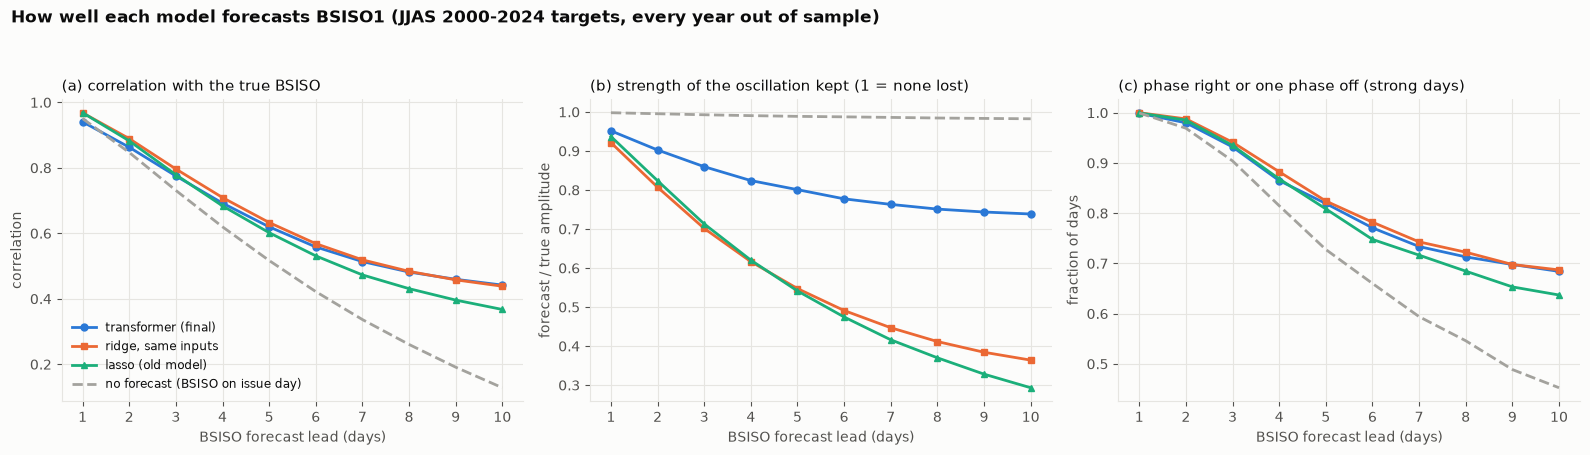

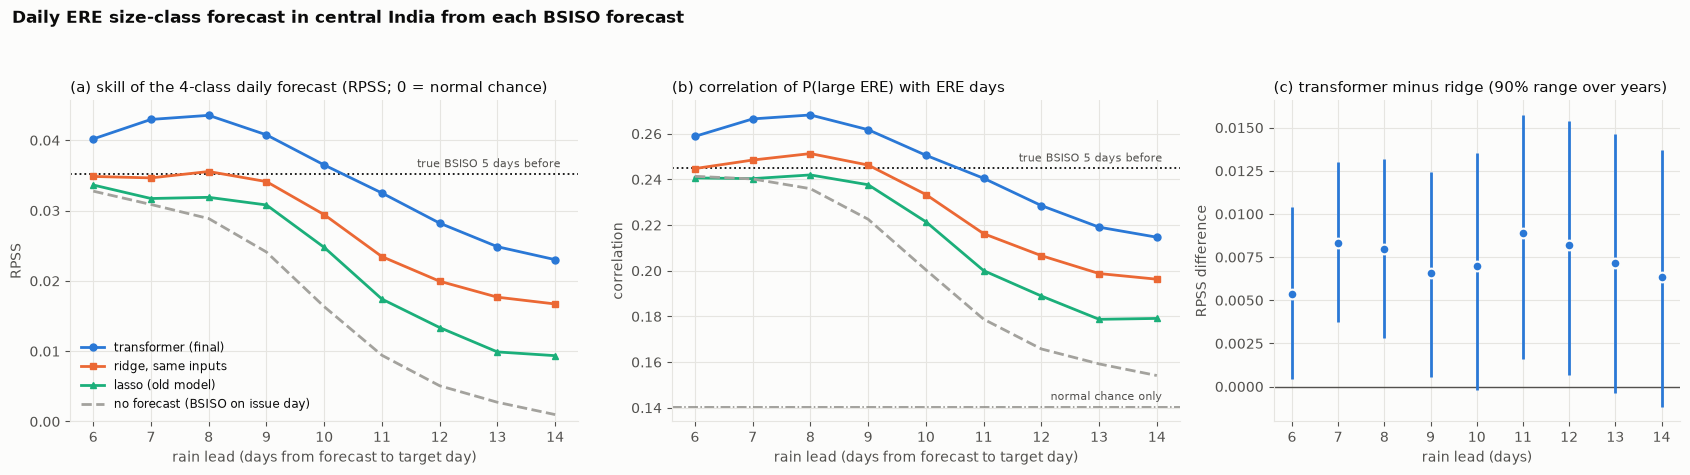

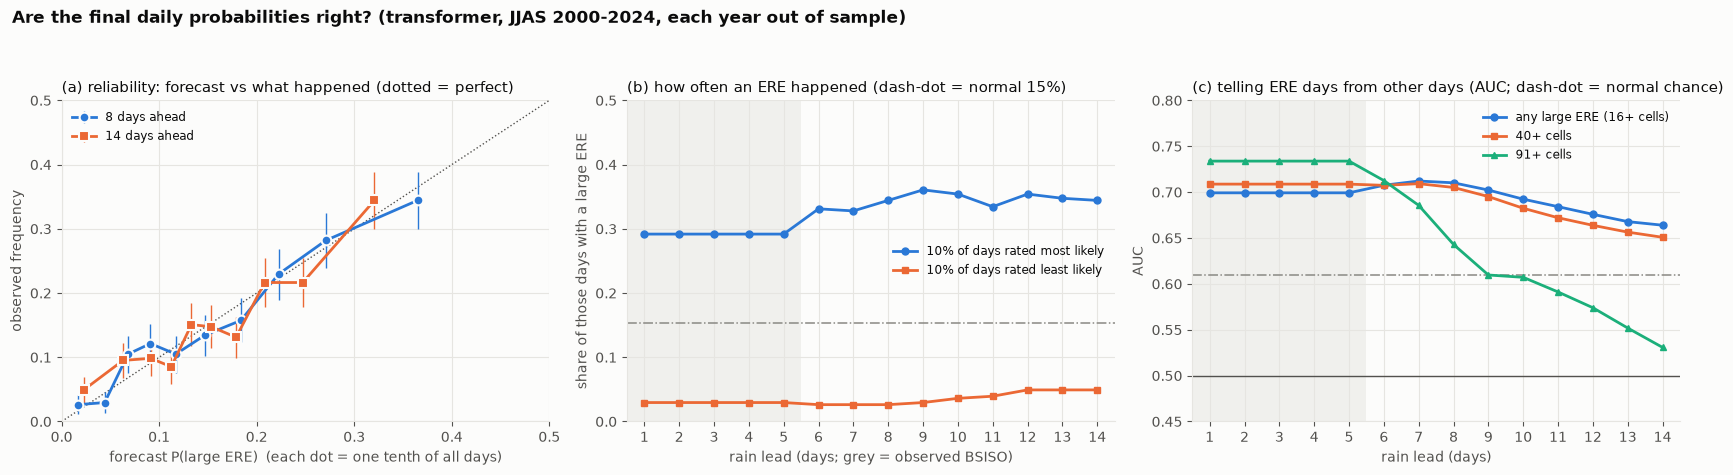

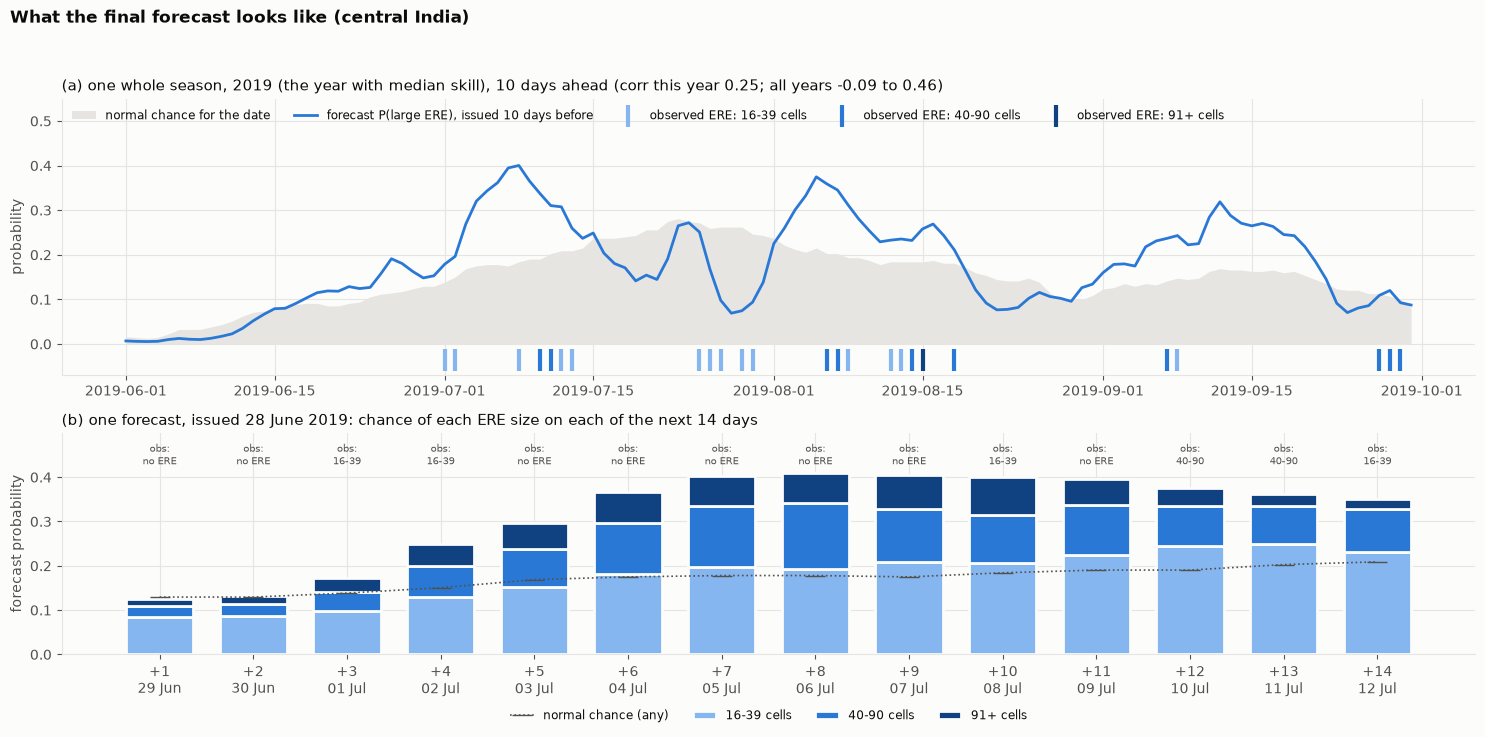

In [10]:
# CELL 10 -- figures 1-4
LAB = {"transformer": ("transformer (final)", BLUE, "-", "o"), "ridge, all inputs": ("ridge, same inputs", ORANGE, "-", "s"),
       "lasso": ("lasso (old model)", AQUA, "-", "^"), "persistence": ("no forecast (BSISO on issue day)", GRAY, "--", None)}
SHOW = [m for m in LAB if m in MODELS]


def save(fig, name):
    fig.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    plt.show()


fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for j, (col, title, ylab) in enumerate((("correlation", "(a) correlation with the true BSISO", "correlation"),
                                        ("amplitude kept", "(b) strength of the oscillation kept (1 = none lost)", "forecast / true amplitude"),
                                        ("phase right or 1 off", "(c) phase right or one phase off (strong days)", "fraction of days"))):
    for nm in SHOW:
        lab, c, ls, mk = LAB[nm]
        v = BS[BS.model == nm].sort_values("lead")
        ax[j].plot(v.lead, v[col], color=c, ls=ls, marker=mk, label=lab)
    ax[j].set(xlabel="BSISO forecast lead (days)", ylabel=ylab, xticks=range(1, 11), title=title)
ax[0].legend(frameon=False, fontsize=8.5, loc="lower left")
fig.suptitle("How well each model forecasts BSISO1 (JJAS 2000-2024 targets, every year out of sample)", x=0.01,
             ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "fig1_bsiso_forecast_accuracy.png")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for j, (col, ref, norm, title) in enumerate((("RPSS", rpss(REF), None, "(a) skill of the 4-class daily forecast (RPSS; 0 = normal chance)"),
                                             ("corr", REF["corr"], ACC["corr normal chance"].iloc[0], "(b) correlation of P(large ERE) with ERE days"))):
    ax[j].axhline(ref, color=INK, ls=":", lw=1.3)
    ax[j].annotate("true BSISO 5 days before", (14, ref), xytext=(4, 5), textcoords="offset points", fontsize=8,
                   color=INK2, ha="right")
    if norm is not None:
        ax[j].axhline(norm, color=MUTED, ls="-.", lw=1.1)
        ax[j].annotate("normal chance only", (14, norm), xytext=(4, 5), textcoords="offset points", fontsize=8,
                       color=INK2, ha="right")
    for nm in SHOW:
        lab, c, ls, mk = LAB[nm]
        v = RAIN[(RAIN.model == nm) & (RAIN.lead >= 6)]
        ax[j].plot(v.lead, v[col], color=c, ls=ls, marker=mk, label=lab)
    ax[j].set(xlabel="rain lead (days from forecast to target day)", ylabel={"corr": "correlation"}.get(col, col),
              xticks=range(6, 15), title=title)
ax[0].set_ylim(bottom=min(0, RAIN.RPSS.min()))
ax[0].legend(frameon=False, fontsize=8.5, loc="lower left")
c_ = RCMP[RCMP["vs"] == "ridge, all inputs"]
ax[2].axhline(0, color=INK2, lw=1)
ax[2].errorbar(c_.lead, c_["RPSS difference"], yerr=[c_["RPSS difference"] - c_["90% low"], c_["90% high"] - c_["RPSS difference"]],
               fmt="o", color=BLUE, elinewidth=2, capsize=0, ms=7, mec=SURF, mew=1.5)
ax[2].set(xticks=range(6, 15), xlabel="rain lead (days)", ylabel="RPSS difference",
          title="(c) transformer minus ridge (90% range over years)")
fig.suptitle("Daily ERE size-class forecast in central India from each BSISO forecast", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "fig2_rain_skill.png")

T = TAB.copy()
T["p"], T["pn"], T["o"] = 1 - T["P(no ERE)"], 1 - T["normal P(no ERE)"], (T.observed != "no ERE").astype(int)
AT = ACC[ACC.model == "transformer"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot([0, 0.5], [0, 0.5], color=INK2, lw=1, ls=":")
for L, c, mk in ((8, BLUE, "o"), (14, ORANGE, "s")):
    t = T[T.lead == L].copy()
    t["bin"] = pd.qcut(t.p, 10, labels=False, duplicates="drop")
    g = t.groupby("bin").agg(f=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    ax[0].errorbar(g.f, g.o, yerr=1.645 * np.sqrt(g.o * (1 - g.o) / g.n), fmt=mk + "-", color=c, elinewidth=1,
                   capsize=0, mec=SURF, mew=1.5, ms=7, label=f"{L} days ahead")
ax[0].set(xlim=(0, 0.5), ylim=(0, 0.5), xlabel="forecast P(large ERE)  (each dot = one tenth of all days)",
          ylabel="observed frequency", title="(a) reliability: forecast vs what happened (dotted = perfect)")
ax[0].legend(frameon=False, fontsize=8.5, loc="upper left")
ax[1].axhline(AT["base rate"].mean(), color=MUTED, ls="-.", lw=1.1)
ax[1].plot(AT.lead, AT["hit rate top 10%"], color=BLUE, marker="o", label="10% of days rated most likely")
ax[1].plot(AT.lead, AT["hit rate bottom 10%"], color=ORANGE, marker="s", label="10% of days rated least likely")
ax[1].axvspan(0.5, 5.5, color=GRID, alpha=0.5, lw=0)
ax[1].set(xticks=range(1, 15), xlim=(0.5, 14.5), ylim=(0, 0.5), xlabel="rain lead (days; grey = observed BSISO)",
          ylabel="share of those days with a large ERE", title="(b) how often an ERE happened (dash-dot = normal 15%)")
ax[1].legend(frameon=False, fontsize=8.5, loc="center right")
ax[2].axhline(AT["AUC normal chance"].iloc[0], color=MUTED, ls="-.", lw=1.1)
ax[2].axhline(0.5, color=INK2, lw=1)
for col, lab, c, mk in (("AUC", "any large ERE (16+ cells)", BLUE, "o"), ("AUC 40+ cells", "40+ cells", ORANGE, "s"),
                        ("AUC 91+ cells", "91+ cells", AQUA, "^")):
    ax[2].plot(AT.lead, AT[col], color=c, marker=mk, label=lab)
ax[2].axvspan(0.5, 5.5, color=GRID, alpha=0.5, lw=0)
ax[2].set(xticks=range(1, 15), xlim=(0.5, 14.5), ylim=(0.45, 0.8), xlabel="rain lead (days)", ylabel="AUC",
          title="(c) telling ERE days from other days (AUC; dash-dot = normal chance)")
ax[2].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Are the final daily probabilities right? (transformer, JJAS 2000-2024, each year out of sample)", x=0.01,
             ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "fig3_probability_accuracy.png")

t10 = T[T.lead == 10].copy(); t10["year"] = t10.target.dt.year
yc = t10.groupby("year").apply(lambda d: np.corrcoef(d.p, d.o)[0, 1] if d.o.sum() else np.nan).dropna()
YEX = int((yc - yc.median()).abs().idxmin())                       # the median-skill year (not hand-picked)
d = t10[t10.year == YEX]
ccol = {"16-39 cells": "#86b6ef", "40-90 cells": BLUE, "91+ cells": "#104281"}
fig, ax = plt.subplots(2, 1, figsize=(15, 7.5), gridspec_kw={"height_ratios": [1.25, 1]})
ax[0].fill_between(d.target, 0, d.pn, color=GRID, lw=0, label="normal chance for the date")
ax[0].plot(d.target, d.p, color=BLUE, lw=2, label="forecast P(large ERE), issued 10 days before")
for cname, c in ccol.items():
    e = d[d.observed == cname]
    ax[0].scatter(e.target, np.full(len(e), -0.035), marker="|", s=260, color=c, lw=3, label=f"observed ERE: {cname}")
ax[0].set(ylim=(-0.07, max(0.55, d.p.max() + 0.05)), ylabel="probability",
          title=f"(a) one whole season, {YEX} (the year with median skill), 10 days ahead "
                f"(corr this year {yc[YEX]:.2f}; all years {yc.min():.2f} to {yc.max():.2f})")
ax[0].legend(frameon=False, fontsize=8.5, ncol=5, loc="upper left")
ISS = d.sort_values("p").iloc[-1].issue
ex = T[T.issue == ISS].sort_values("lead")
bot = np.zeros(len(ex))
for cname, c in ccol.items():
    v = ex[f"P({cname})"].values
    ax[1].bar(ex.lead, v, bottom=bot, color=c, width=0.72, edgecolor=SURF, lw=2, label=cname)
    bot += v
ax[1].plot(ex.lead, ex.pn, color=INK2, ls=":", marker="_", ms=14, lw=1.2, label="normal chance (any)")
for L_, o in zip(ex.lead, ex.observed):
    ax[1].annotate("obs:\n" + o.replace(" cells", ""), (L_, bot.max() + 0.02), ha="center", fontsize=7.5, color=INK2)
ax[1].set(xticks=ex.lead, xticklabels=[f"+{L_}\n{dd:%d %b}" for L_, dd in zip(ex.lead, ex.target)],
          ylim=(0, bot.max() + 0.09), ylabel="forecast probability",
          title=f"(b) one forecast, issued {ISS:%d %B %Y}: chance of each ERE size on each of the next 14 days")
ax[1].legend(frameon=False, fontsize=8.5, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.suptitle("What the final forecast looks like (central India)", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "fig4_example_forecasts.png")

### Figures 5-6

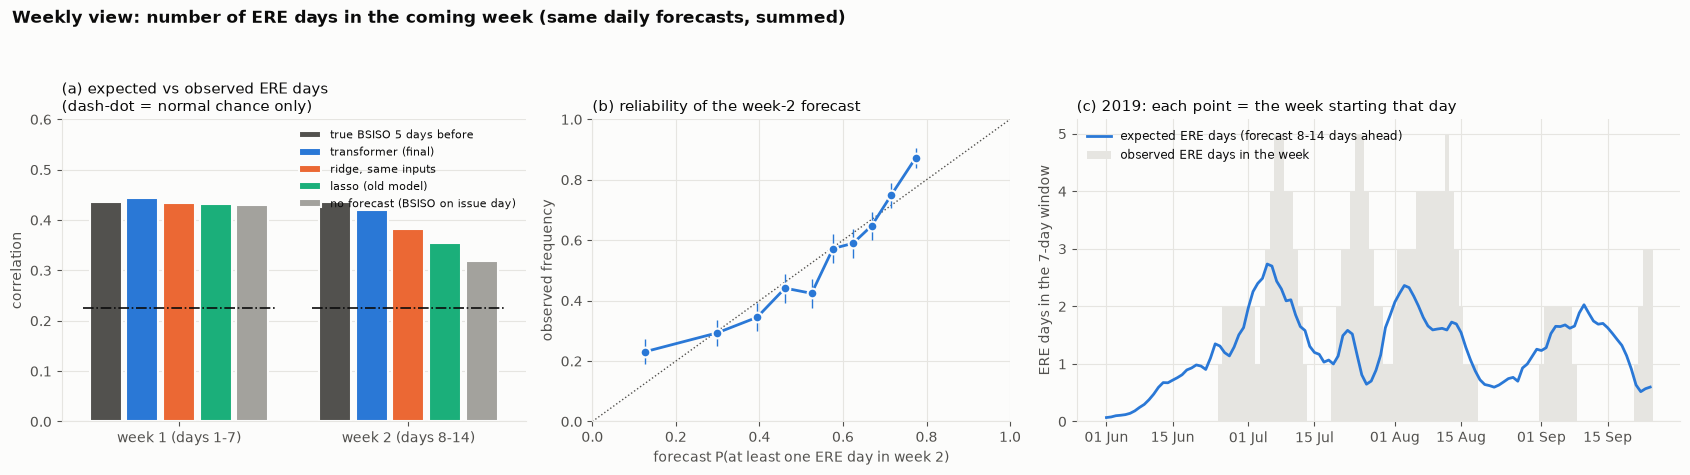

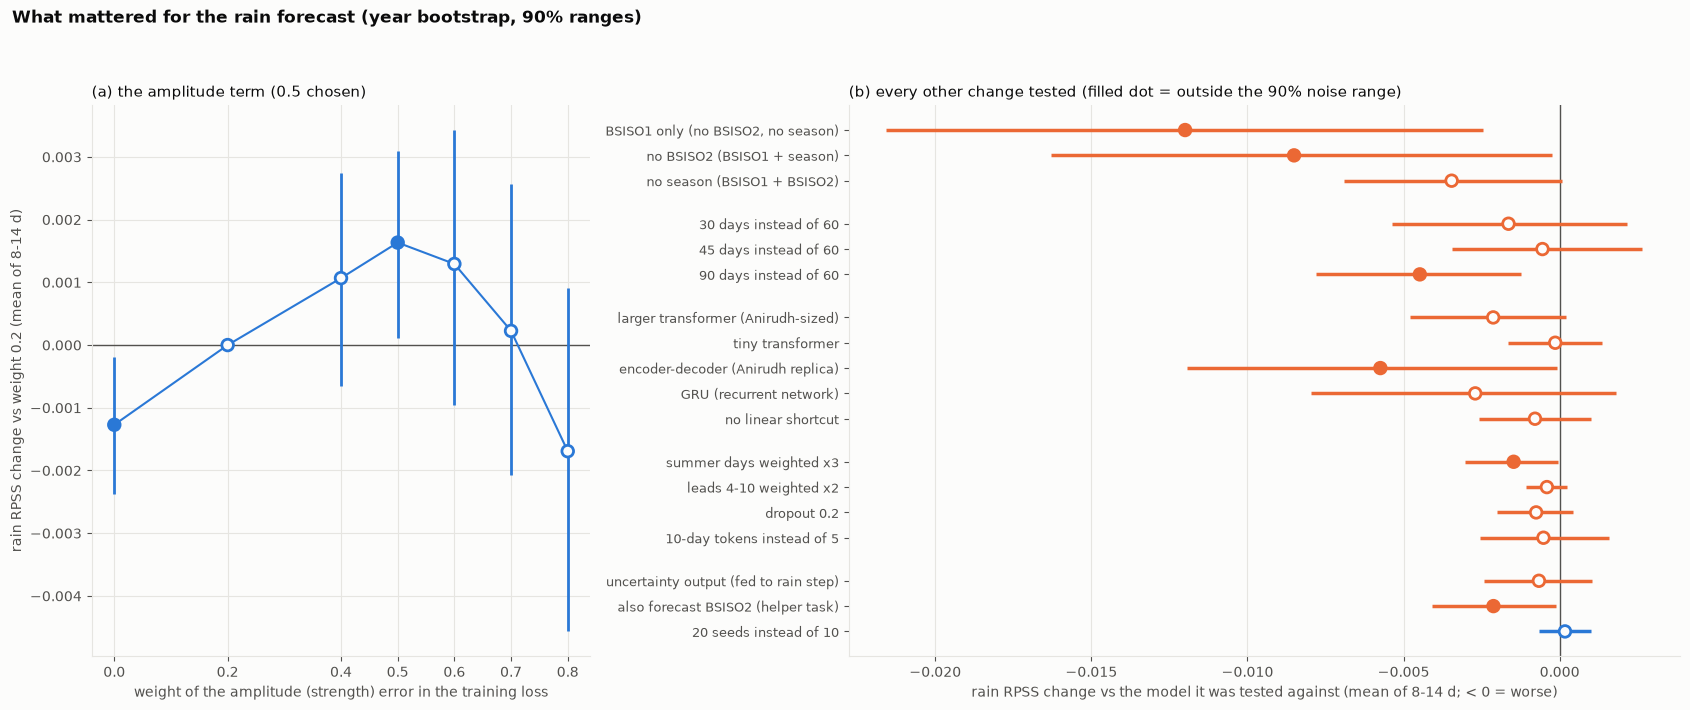


SUMMARY
                    RPSS                               corr                \
lead                  5      8      10     12     14     5      8      10   
model                                                                       
lasso              0.035  0.032  0.025  0.013  0.009  0.245  0.242  0.221   
observed           0.035  0.035  0.035  0.035  0.035  0.245  0.245  0.245   
ridge, all inputs  0.035  0.036  0.029  0.020  0.017  0.245  0.251  0.233   
transformer        0.035  0.044  0.036  0.028  0.023  0.245  0.268  0.251   

                                 
lead                  12     14  
model                            
lasso              0.189  0.179  
observed           0.245  0.245  
ridge, all inputs  0.207  0.196  
transformer        0.229  0.215  
            window             model  RPSS (0/1/2+)  corr expected vs observed count  corr, normal chance  AUC any ERE day  AUC 2+ ERE days
 week 1 (days 1-7)          observed          0.129                      

In [11]:
# CELL 11 -- figures 5-6
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 0.9, 1.3]})
xs = np.arange(len(WEEKS))
order = [m for m in ["observed"] + SHOW if m in ALLR]
cols = {"observed": INK2, **{k: v[1] for k, v in LAB.items()}}
wid = 0.8 / len(order)
for i, nm in enumerate(order):
    v = WS[WS.model == nm]["corr expected vs observed count"].values
    ax[0].bar(xs + (i - (len(order) - 1) / 2) * wid, v, width=wid - 0.02, color=cols[nm], edgecolor=SURF, lw=1.5,
              label={"observed": "true BSISO 5 days before"}.get(nm, LAB.get(nm, (nm,))[0]))
nrm = WS[WS.model == "transformer"]["corr, normal chance"].values
for i, x0 in enumerate(xs):
    ax[0].hlines(nrm[i], x0 - 0.42, x0 + 0.42, color=INK, ls="-.", lw=1.2)
ax[0].set(xticks=xs, xticklabels=list(WEEKS), ylabel="correlation", ylim=(0, 0.6),
          title="(a) expected vs observed ERE days\n(dash-dot = normal chance only)")
ax[0].legend(frameon=False, fontsize=8, loc="upper right")
ax[0].grid(axis="x", visible=False)
wk2 = list(WEEKS)[1]
r = WE[(wk2, "transformer")]
g_ = r["G"]
dfw = pd.DataFrame({"p": r["P"][0][g_], "o": (NW[g_] >= 1).astype(int)})
dfw["bin"] = pd.qcut(dfw.p, 10, labels=False, duplicates="drop")
gg = dfw.groupby("bin").agg(f=("p", "mean"), o=("o", "mean"), n=("o", "size"))
ax[1].plot([0, 1], [0, 1], color=INK2, lw=1, ls=":")
ax[1].errorbar(gg.f, gg.o, yerr=1.645 * np.sqrt(gg.o * (1 - gg.o) / gg.n), fmt="o-", color=BLUE, elinewidth=1,
               capsize=0, mec=SURF, mew=1.5, ms=7)
ax[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="forecast P(at least one ERE day in week 2)", ylabel="observed frequency",
          title="(b) reliability of the week-2 forecast")
wd = pd.DataFrame({"first": times[J], "S": r["S"], "n": NW, "g": g_})
wd = wd[(wd["first"].dt.year == YEX) & wd.g]
ax[2].bar(wd["first"], wd["n"], width=1.0, color=GRID, label="observed ERE days in the week")
ax[2].plot(wd["first"], wd["S"], color=BLUE, lw=2, label="expected ERE days (forecast 8-14 days ahead)")
ax[2].set(ylabel="ERE days in the 7-day window", title=f"(c) {YEX}: each point = the week starting that day")
ax[2].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%d %b"))
ax[2].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("Weekly view: number of ERE days in the coming week (same daily forecasts, summed)", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "fig5_weekly_view.png")

if len(EF):
    fig, ax = plt.subplots(1, 2, figsize=(17, 7.2), gridspec_kw={"width_ratios": [0.75, 1.25]})
    ax[0].axhline(0, color=INK2, lw=1)
    sig = (AM["90% low"] > 0) | (AM["90% high"] < 0)
    ax[0].errorbar(AM.amp_w, AM["RPSS change"], yerr=[AM["RPSS change"] - AM["90% low"], AM["90% high"] - AM["RPSS change"]],
                   fmt="-", color=BLUE, elinewidth=2, capsize=0, lw=1.5)
    ax[0].scatter(AM.amp_w, AM["RPSS change"], s=70, zorder=3, color=np.where(sig, BLUE, SURF), edgecolor=BLUE, lw=2)
    ax[0].set(xticks=AM.amp_w, xlabel="weight of the amplitude (strength) error in the training loss",
              ylabel="rain RPSS change vs weight 0.2 (mean of 8-14 d)", title="(a) the amplitude term (0.5 chosen)")
    EFp = EF.iloc[::-1].reset_index(drop=True)
    ypos, yy, prev = [], 0, None
    for _, rr in EFp.iterrows():
        if prev is not None and rr.group != prev:
            yy += 0.7
        ypos.append(yy); prev = rr.group; yy += 1
    ypos = np.array(ypos)
    neg = EFp["RPSS change"] < 0
    s1 = (EFp["90% low"] > 0) | (EFp["90% high"] < 0)
    ax[1].axvline(0, color=INK2, lw=1)
    ax[1].hlines(ypos, EFp["90% low"], EFp["90% high"], color=np.where(neg, ORANGE, BLUE), lw=2.5)
    ax[1].scatter(EFp["RPSS change"], ypos, s=70, zorder=3, color=np.where(s1, np.where(neg, ORANGE, BLUE), SURF),
                  edgecolor=np.where(neg, ORANGE, BLUE), lw=2)
    ax[1].set_yticks(ypos, EFp.change, fontsize=9)
    ax[1].grid(axis="y", visible=False)
    ax[1].set(xlabel="rain RPSS change vs the model it was tested against (mean of 8-14 d; < 0 = worse)",
              title="(b) every other change tested (filled dot = outside the 90% noise range)")
    fig.suptitle("What mattered for the rain forecast (year bootstrap, 90% ranges)", x=0.01, ha="left", fontsize=12.5,
                 fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    save(fig, "fig6_what_mattered.png")

print("\nSUMMARY")
print(RAIN[(RAIN.model.isin(["observed", "transformer", "ridge, all inputs", "lasso"])) & RAIN.lead.isin([5, 8, 10, 12, 14])]
      .pivot(index="model", columns="lead", values=["RPSS", "corr"]).round(3))
print(WS.round(3).to_string(index=False))